# The 40-20 Rule: Does It Predict NBA Championship Contenders?

*All code and markdowns are written by Jawad Kazma.*

## The 40-20 Rule

In this notebook, I explore trends in NBA team performance across seasons using what's known as "The 40-20 Rule." First proposed by legendary head coach Phil Jackson around the 2007-08 season, the rule states that a team must win 40 games before its 20th loss to be considered a championship contender that season. The rule applies to all NBA seasons from 1979-80 onward, coinciding with the introduction of the three-point line. While this "rule" is obviously not a strict law, it reflects a coaching philosophy based on an observed pattern across NBA history (think of it like when people say "Defense wins championships!"). Many NBA champions have achieved this milestone, while others have failed to win a title despite meeting the rule's requirements.

The purpose of this investigation is to explore whether there is any validity to Phil Jackson's "40 before 20" benchmark and what correlation (if any) it has with playoff success and winning a championship. To find out, I created an interactive dashboard with several visualizations (bar charts, dot plots, timelines, and violin plots) to observe trends in team performance and how they support or defy the 40-20 Rule.

## Visualization Techniques

I chose four visualization types that each highlight a different aspect of team performance:

- **Bar Chart** - Shows how many teams passed the 40-20 Rule, grouped by their final playoff result. I also look at whether teams had 50 wins before 20 losses, 60 wins before 20 losses, and even 40 wins before 10 losses. This shows how frequently each rule has been met and how those teams were distributed across levels of playoff success.
- **Dot Plot** - Plots a team's win percentage against its playoff seed, with colors indicating the team's playoff result. This shows whether regular-season dominance translates to the postseason, and its correlation with a deep playoff run or a championship.
- **Timeline Plot** - Shows the date each team reached its 40th win, highlighting how early in the season each team achieved this goal. A timeline reveals trends in regular-season pacing and efficiency.
- **Violin Plot** - Compares the distribution of win percentage across each playoff result category. The shapes reveal whether teams cluster around certain win percentages at each stage of the playoffs, which is useful for seeing variance across teams, comparing the consistency of top-seeded teams, and uncovering unpredictable postseason outcomes.

Together, these visualizations give a big-picture view (bar and violin plots) and a closer look at individual teams (dot and timeline plots). The charts are interactive: hover for team details and click legend entries to filter groups in and out.

## Visualization Library

I chose to use **Plotly Express** because I am familiar with it and have used it before. I like how the visuals look, it is compatible with Jupyter notebooks, and I really like the interactivity and clean visualizations it creates for dashboards. Plotly is open source and developed by Plotly Inc. Documentation: https://plotly.com/python/

To install Plotly, use this command:

```
pip install plotly
```

## Demonstration

### Import Libraries

Here's the list of libraries used for data cleaning and visualizations:

In [1]:
# needed to clean the data using dataframes
import pandas as pd
import numpy as np

# needed to build the dashboard
import plotly.express as px
import plotly.io as pio

# show interactive charts and also embed a static PNG of each one so they display on GitHub
# (the PNG step needs the optional `kaleido` package; without it the charts are just interactive)
try:
    import kaleido  # noqa: F401
    pio.renderers.default = "notebook+png"
except ImportError:
    pass  # keep Plotly's default renderer

# ignores warnings
import warnings
warnings.filterwarnings('ignore')

### Cleaning the Dataset

Unfortunately, I had no choice but to construct the dataset by hand using [basketball-reference.com](https://www.basketball-reference.com), since there were no Excel sheets or APIs available to export data from. The statistics I needed were very specific, so doing it by hand felt more justifiable than trying a different method. Normally I would not go down this route for data collection, but since I am well-researched on this topic and very interested in it, it was actually a pretty fun challenge! It also worked in my favor: the dataset is relatively small (only around 200 rows) and the spreadsheet is clean.

Now let's import the `.csv` file and see what the dataset looks like.

In [2]:
# import data set
df = pd.read_csv('nba_team_milestones.csv')
df.head()

,Season,Shortened_Season,Team,Wins,Losses,Win_Pct,Standing,Conference,Hit_40_Before_20,Hit_50_Before_20,Hit_60_Before_20,Hit_40_Before_10,Date_40th_Win,Record_40th_Win,Playoff_Result
0,1979-80,No,Los Angeles Lakers,60,22,0.732,1st,West,Yes,No,No,No,2/8/1980,40-17,Champions
1,1979-80,No,Boston Celtics,61,21,0.744,1st,East,Yes,Yes,No,No,1/30/1980,40-13,Conf Finals
2,1979-80,No,Philadelphia 76ers,59,23,0.720,3rd,East,Yes,Yes,No,No,2/10/1980,40-16,Finals
3,1979-80,No,Seattle Super Sonics,56,26,0.683,3rd,West,Yes,No,No,No,2/7/1980,40-16,Conf Finals
4,1980-81,No,Boston Celtics,62,20,0.756,1st,East,Yes,Yes,Yes,Yes,1/21/1981,40-9,Champions


Everything looks pretty straightforward: all the columns are named appropriately, and the data is clean and readable. However, if you're someone who doesn't watch basketball, this dataframe won't tell you a lot.

We can filter the data to show us some neat things. For example, let's see whether every championship-winning team passed the 40-20 Rule.

In [3]:
# dataframe of teams that won the NBA championship but did NOT pass the 40-20 Rule
champions_under40start_df = df[(df['Playoff_Result'] == 'Champions') & (df['Hit_40_Before_20'] == 'No')].iloc[:, :8]  # display only first 8 columns
champions_under40start_df

,Season,Shortened_Season,Team,Wins,Losses,Win_Pct,Standing,Conference
58,1994-95,No,Houston Rockets,47,35,0.573,6th,West
83,1998-99,Yes,San Antonio Spurs,37,13,0.740,1st,West
103,2003-04,No,Detroit Pistons,54,28,0.659,3rd,East
110,2005-06,No,Miami Heat,52,30,0.634,2nd,East
180,2020-21,Yes,Milwaukee Bucks,46,26,0.639,3rd,East


Very interesting: all but 5 NBA championship teams since the 1979-80 season have passed the 40-20 Rule. That's 41 out of 46 teams! Maybe Phil Jackson was on to something...

Even more interesting is that 2 of these 5 teams played in shortened seasons instead of the regular 82-game season.

Now let's see which other teams played during shortened seasons and reached 40 wins before 20 losses.

In [4]:
# dataframe of teams that played during shortened seasons
shortened_seasons_df = df[df['Shortened_Season'] == 'Yes'].iloc[:, :9]  # display only first 9 columns
shortened_seasons_df = shortened_seasons_df.drop('Shortened_Season', axis=1)  # drop this column as it is redundant
shortened_seasons_df

,Season,Team,Wins,Losses,Win_Pct,Standing,Conference,Hit_40_Before_20
83,1998-99,San Antonio Spurs,37,13,0.740,1st,West,No
84,1998-99,Portland Trail Blazers,35,15,0.700,2nd,West,No
85,1998-99,Utah Jazz,37,13,0.740,3rd,West,No
136,2011-12,Miami Heat,46,20,0.697,2nd,East,Yes
137,2011-12,San Antonio Spurs,50,16,0.758,1st,West,Yes
138,2011-12,Chicago Bulls,50,16,0.758,1st,East,Yes
139,2011-12,Oklahoma City Thunder,47,19,0.712,2nd,West,Yes
173,2019-20,Los Angeles Lakers,52,19,0.732,1st,West,Yes
174,2019-20,Milwaukee Bucks,56,17,0.767,1st,East,Yes
175,2019-20,Toronto Raptors,53,19,0.736,2nd,East,Yes


Looking at this list, we must treat the data carefully and apply some context.

- **1998-99:** A lockout shortened the season to 50 games. Any data from this season should be considered an outlier, but I kept it in the dataset on purpose because all 3 teams listed from that year were on pace to possibly pass the 40-20 Rule.
- **2011-12:** Another lockout shortened the season to 66 games. Multiple teams were still able to meet the requirements of the 40-20 Rule.
- **2019-20 and 2020-21:** Both seasons were shortened due to COVID-19, so only 71 and 72 games were played, respectively. Many teams still passed the 40-20 Rule, except for the team that won the 2020-21 NBA Championship: the Milwaukee Bucks (isn't that crazy?!).

That's a little insight into what the data says at first glance, but that's only through dataframes. Now it's time to create the visualizations and build the dashboard so we can really see how well the 40-20 Rule holds.

## 1. Bar Chart

To create the bar chart, this function cleans up the data and plots the chart with Plotly Express.

The number of teams that reached each benchmark is counted and charted in groups based on their playoff outcomes.

In [5]:
def bar_chart():
    # filter by benchmark and get the counts of every team that hit each one
    benchmark_list = ['Hit_40_Before_20', 'Hit_50_Before_20', 'Hit_60_Before_20', 'Hit_40_Before_10']
    benchmark_counts = df.groupby('Playoff_Result')[benchmark_list].apply(lambda x: (x == 'Yes').sum())

    # convert from a series to a dataframe
    benchmark_counts_df = benchmark_counts.stack().reset_index()
    benchmark_counts_df.columns = ['Playoff_Result', 'Benchmark', 'Count']

    # edit benchmark column names for readability in the bar chart
    names = {
        'Hit_40_Before_20': '40 Before 20',
        'Hit_50_Before_20': '50 Before 20',
        'Hit_60_Before_20': '60 Before 20',
        'Hit_40_Before_10': '40 Before 10'
    }
    benchmark_counts_df['Benchmark'] = benchmark_counts_df['Benchmark'].map(names)

    # plot the bar chart with Plotly Express
    fig = px.bar(
        benchmark_counts_df,
        x='Playoff_Result',
        y='Count',
        color='Benchmark',
        title='Benchmarks Reached by Teams at Each Playoff Stage',
        # changes names of x-axis, y-axis, and legend
        labels={
            'Count': 'Number of Teams',
            'Playoff_Result': 'Playoff Result',
            'Benchmark': 'Rule'
        },
        # shows only the counts when hovering over a bar
        hover_data={
            'Playoff_Result': False,
            'Benchmark': False,
            'Count': True
        },
        # allows for displaying groups in correct order
        category_orders={
            'Playoff_Result': [
                'Champions',
                'Finals',
                'Conf Finals',
                'Conf Semis',
                'First Round'
            ]
        },
        barmode='group'
    )

    # centers the title
    fig.update_layout(
        title={'x': 0.5, 'xanchor': 'center'}
    )

    fig.show()

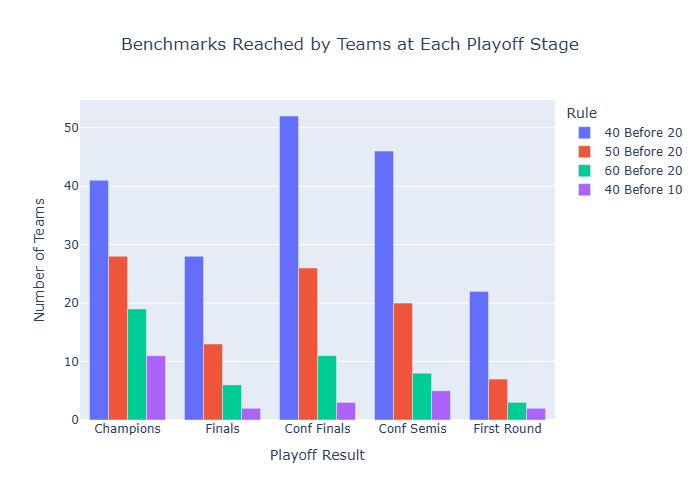

In [6]:
# call the function in order to output the bar chart
bar_chart()

Now let's look at what the bar chart shows. The playoff results are displayed in groups on the x-axis, the number of teams is on the y-axis, and the colors show which benchmark each team hit.

At first glance, the hardest benchmark, winning 40 before losing 10, was achieved most by teams that were NBA champions. The second hardest benchmark, 60 wins before 20 losses, was also achieved most by NBA champions. This supports the idea that across NBA history, championship seasons have often coincided with dominant regular-season performances.

It's important to note, however, that only a certain number of teams can reach each playoff stage, since the NBA playoffs are a knockout tournament. Here's the breakdown:

- A total of 30 teams make up the NBA. In the 1979-80 season there were only 22 teams, and the league has expanded since.
- The playoffs consist of 4 knockout rounds: First Round, Conference Semifinals, Conference Finals, and NBA Finals.
- 16 teams qualify for the playoffs and start in the First Round: 8 from each conference (East and West). This format started with the 1983-84 playoffs; previously only 12 teams qualified.
- 8 teams advance to the Conference Semifinals (4 from each conference).
- 4 teams advance to the Conference Finals (2 from each conference).
- 2 teams face off in the NBA Finals.
- 1 team is crowned NBA Champions.

I've included this information to give better context for the counts at each playoff result. It's natural for the tallest bars to come from the earlier playoff stages, since the number of teams advancing gets smaller and smaller. Nevertheless, there are interesting insights in the chart, such as the fact that it is common for more than one team to pass the 40-20 Rule in a single NBA season. Most of these teams seem to be eliminated around the Conference Semifinals and Conference Finals.

Also, since the 40-20 Rule helps identify elite teams in every season, one way to see who is considered the best of the best is by filtering the benchmarks in the legend. Click on each color to make that benchmark disappear from the chart and compare the playoff result groups.

## 2. Dot Plot

Time to build the dot plot. We can use the same logic as the `bar_chart()` function, with some minor changes.

In [7]:
def dot_plot():
    # filter out all teams that did not win a championship and did not hit 40-20
    filtered_df = df[(df['Playoff_Result'] == 'Champions') | (df['Hit_40_Before_20'] == 'Yes')].copy()

    # convert standings from strings to ints so that you can add jitter
    filtered_df['Standing'] = filtered_df['Standing'].str.extract(r'(\d+)').astype(int)

    # add jitter to the plot so that teams with the same record and seed aren't stacked on top of each other
    rng = np.random.default_rng(42)  # fixed seed so the plot looks the same every run
    filtered_df['Standings_Jittered'] = filtered_df['Standing'] + rng.uniform(-0.025, 0.025, size=len(filtered_df))

    # plot the dot plot with Plotly Express
    fig = px.scatter(
        filtered_df,
        x='Standings_Jittered',
        y='Win_Pct',
        color='Playoff_Result',
        title='Playoff Seed vs Win %',
        labels={
            'Win_Pct': 'Win %',
            'Standings_Jittered': 'Playoff Seed',
            'Playoff_Result': 'Playoff Result'
        },
        # shows season, team, conference, wins, and losses when hovering over a point
        hover_data={
            'Standings_Jittered': False,
            'Win_Pct': False,
            'Standing': False,
            'Playoff_Result': False,
            'Season': True,
            'Team': True,
            'Conference': True,
            'Wins': True,
            'Losses': True
        },
        # allows for displaying groups in correct order
        category_orders={
            'Standing': [
                '1st',
                '2nd',
                '3rd',
                '4th',
                '5th',
                '6th',
                '7th'
            ],
            'Playoff_Result': [
                'Champions',
                'Finals',
                'Conf Finals',
                'Conf Semis',
                'First Round'
            ]
        },
        height=600
    )

    # centers the title
    fig.update_layout(
        title={'x': 0.5, 'xanchor': 'center'}
    )

    fig.show()

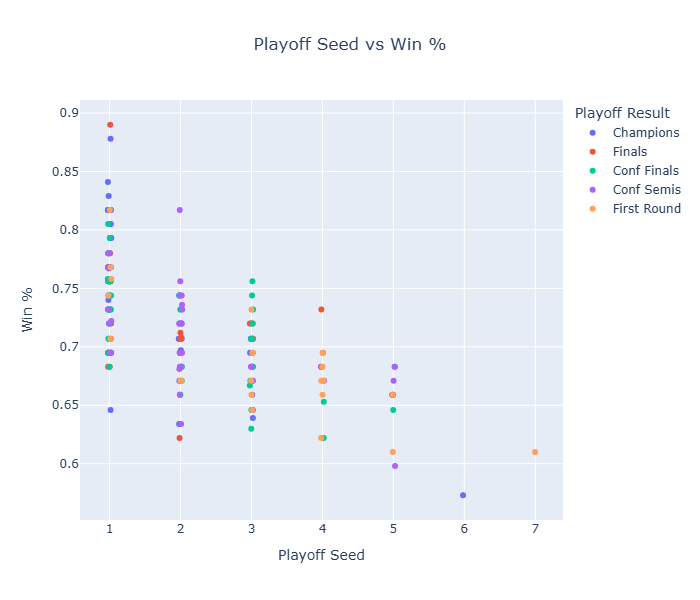

In [8]:
# call the function in order to output the dot plot
dot_plot()

Here we've plotted every team that either won a championship or hit the 40-20 Rule, organized by playoff seed within their conference. Instead of plotting against win total, I chose win percentage because a number of teams played in shortened seasons. I added a little jitter so that points would not stack on top of each other and hide teams. Interactivity works the same way as the bar chart: clicking a playoff result in the legend filters it out.

### The Outliers

It makes sense that the highest number of teams to reach 40-20 were 1st seeds. The total number of teams at each seed gets slightly smaller, with two outliers in the 6th and 7th seeds. Most 1st and 2nd seeds finished with win percentages in the .700 to .800 range. As the chart shows, there is overlap in win percentage between neighboring seeds, which suggests that slight differences in record have a big impact on seeding in stronger conferences. The only 40-20 team that was a 7th seed was the 2000-01 Portland Trail Blazers, posting a 50-32 record, which suggests the Western Conference was incredibly competitive that season.

It's worth noting that this plot includes teams that either were NBA champions OR hit the 40-20 Rule. As we discovered when exploring the `.csv` file, only 5 championship teams did not pass the 40-20 Rule. Take a look at the clear outlier in the 6th seed group: the 1994-95 Houston Rockets. In my opinion, it's the most interesting team in this whole dataset. Despite winning the NBA championship, they didn't even win 50 games, posting a 47-35 record. How on Earth did that happen?

This would be a head-scratcher for someone who didn't watch the NBA in the 90s. The year before, the Rockets finished 58-24 and won the NBA championship, led by center Hakeem Olajuwon, who was the league's Most Valuable Player in 1993-94. A lot of people at the time pointed to the fact that Michael Jordan, the best player in the league, had left the NBA, and argued the Rockets' championship didn't hold any weight. After all, Jordan and the Chicago Bulls had dominated the 90s up to that point and became one of only three teams (at the time) in NBA history to win 3 consecutive championships (1991-1993). To be fair to the Rockets, they faced some early struggles in 1994-95 due to injuries and slight chemistry issues, as the front office made a couple of in-season trades in an attempt to strengthen the team.

Despite the rocky regular season, the 1994-95 Houston Rockets produced one of the most remarkable championship runs in sports history. In every round of the playoffs that season, the Rockets faced a team that had passed the 40-20 Rule: the 94-95 Utah Jazz, the 94-95 Phoenix Suns, the 94-95 San Antonio Spurs, and the 94-95 Orlando Magic.

- **First Round:** They went the distance with the Jazz, winning 3-2 in a best-of-5 series after starting out in a 2-1 deficit.
- **Conference Semifinals:** They took the Suns to 7 games and won 4-3, coming back from being down 0-2 and 1-3 without home court advantage.
- **Conference Finals:** They took down the 1st-seeded Spurs in 6 games.
- **NBA Finals:** They swept the Magic 4-0.

The 1994-95 Houston Rockets remain the lowest-seeded team to ever win an NBA championship and are the only team in NBA history to successfully defend a championship with a Finals sweep. And guess what? Michael Jordan did come back during the 1994-95 season, but the Bulls lost 4-2 to the Magic in the Eastern Conference Semifinals. So it looks like the Rockets were able to walk the walk (and man, was it a LONG walk).

## 3. Timeline Plot

The timeline plot follows the same logic as the two functions above, with slight modifications.

In [9]:
def timeline_plot():
    date_40th_win_df = df.copy()

    # convert date column to datetime format
    date_40th_win_df['Date_40th_Win'] = pd.to_datetime(date_40th_win_df['Date_40th_Win'])

    # normalize dataframe for month and day of date; use 2000 as a placeholder for the year
    date_40th_win_df['Date_Normalized'] = date_40th_win_df['Date_40th_Win'].apply(lambda x: x.replace(year=2000))

    # shows only day, month, and year (no time)
    date_40th_win_df['Date_40th_Win'] = date_40th_win_df['Date_40th_Win'].dt.strftime('%B %d, %Y')

    # sort and categorize seasons properly
    sorted_seasons = sorted(date_40th_win_df['Season'].unique(), key=lambda x: int(x[:4]))
    date_40th_win_df['Season'] = pd.Categorical(date_40th_win_df['Season'], categories=sorted_seasons, ordered=True)

    fig = px.scatter(
        date_40th_win_df,
        x='Date_Normalized',
        y='Season',
        color='Playoff_Result',
        title='Timeline of Each 40th Win (40-20 Teams)',
        labels={
            'Date_Normalized': 'Date of 40th Win',
            'Season': 'NBA Season',
            'Playoff_Result': 'Playoff Result',
            'Record_40th_Win': 'Record at 40th Win',
            'Date_40th_Win': 'Date'
        },
        hover_data={
            'Team': True,
            'Season': True,
            'Date_40th_Win': True,
            'Record_40th_Win': True,
            'Date_Normalized': False,
            'Playoff_Result': False,
        },
        height=700
    )

    # centers the title
    fig.update_layout(
        title={'x': 0.5, 'xanchor': 'center'},
    )

    # formatting of the x-axis labels for the months
    fig.update_xaxes(
        tickformat="%b",
        tickvals=[
            "2000-01-15",  # Mid-Jan
            "2000-02-15",  # Mid-Feb
            "2000-03-15",  # Mid-Mar
            "2000-04-15"   # Mid-Apr
        ],
        range=["2000-01-01", "2000-04-30"]
    )
    fig.update_yaxes(type='category')

    fig.show()

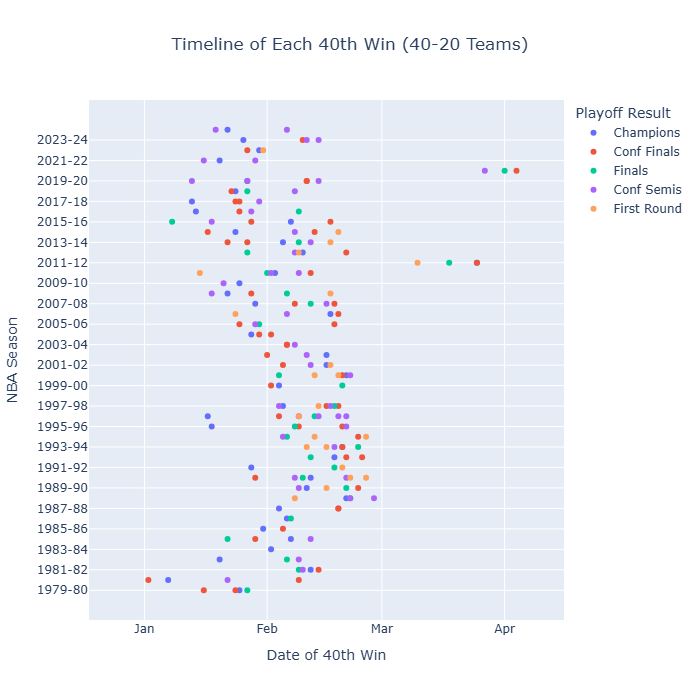

In [10]:
# call the function in order to output the timeline plot
timeline_plot()

Here's a look at when each 40-20 team achieved its 40th win. Since there are 82 games in an NBA season, reaching the 40-20 mark takes at most 59 games (a 40-19 record), so we would expect these dates to fall in the second half of the season, starting in January. The earlier a team reaches this mark, the more dominant it is, since it takes fewer games to reach the benchmark.

Another key insight is how evenly spread these teams are across playoff outcomes. While the majority of NBA Champions and Finals teams reach 40 wins fairly early, some Conference Semifinalists and First Round exits do so just as fast.

## 4. Violin Plot

The violin plot follows the same logic as the timeline plot function above, with slight modifications.

In [11]:
def violin_plot():
    # use the full dataset
    hit_40_20_df = df.copy()

    fig = px.violin(
        hit_40_20_df,
        y='Win_Pct',
        x='Playoff_Result',
        color='Playoff_Result',
        # shows inner box plot for quartiles
        box=True,
        # shows all data points
        points='all',
        hover_data={
            'Team': True,
            'Season': True,
            'Win_Pct': True
        },
        title='Win Percentage Distribution by Playoff Result',
        labels={
            'Win_Pct': 'Win Percentage',
            'Playoff_Result': 'Playoff Result'
        },
        category_orders={
            'Playoff_Result': [
                'Champions',
                'Finals',
                'Conf Finals',
                'Conf Semis',
                'First Round'
            ]
        },
        height=600
    )

    # centers the title
    fig.update_layout(
        title={'x': 0.5, 'xanchor': 'center'},
    )

    fig.show()

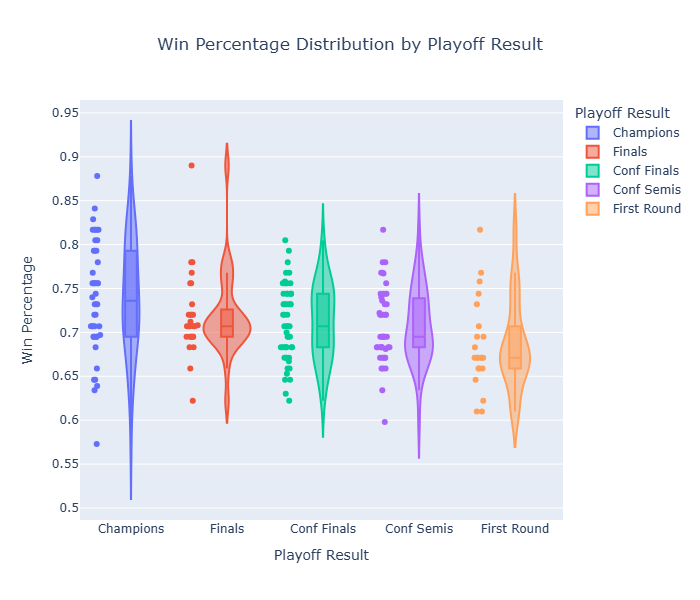

In [12]:
# call the function in order to output the violin plot
violin_plot()

This violin plot shows the distribution of team win percentage by playoff result. We can see how tightly or loosely win percentages cluster depending on a team's postseason success. Teams that were Champions or reached the Finals tend to be more concentrated and have higher win percentages, while teams that lost in earlier rounds are more spread out and vary more. Taking a closer look, First Round exits show a wider distribution, suggesting that some teams possibly overperformed during the regular season or played in a competitive conference.

## Summary

Across this dataset, we've explored the 40-20 Rule and whether this benchmark has any validity as a predictor of postseason success. Through interactive visuals, we saw teams that hit different tiers of benchmarks (40-20, 50-20, 60-20, 40-10), when during the season they hit the 40-20 mark, and how far they advanced in the playoffs.

The biggest takeaway from this experiment is that 41 out of 46 NBA champions passed the 40-20 Rule. This suggests the benchmark is a strong indicator of whether a team is a legitimate contender. These 40-20 teams historically tend to finish with elite records and have better chances of making deep playoff runs.

Although it's not a 100% guarantee, the 40-20 Rule does help show which teams are good and which teams are stamped into NBA lore. It's a simple yet interesting statistic that captures a team's momentum from the regular season to the playoffs, its dominance, and its consistency across multiple seasons.